# Лабораторная работа №2. Сетевая задача и дискретная оптимизация

**Вариант 4**

## Цель работы
Освоить алгоритмы на сетях (максимальный поток, разрез) и методы
дискретной оптимизации (рекурсия, мемоизация, динамическое
программирование, жадные алгоритмы) на примере трёх задач.

## Задачи
1. Для сети с источником $s$ и стоком $t$ найти максимальный поток,
   минимальный разрез, проверить теорему Форда–Фалкерсона и предложить
   способ увеличения максимального потока.
2. Вычислить $N$-е число Фибоначчи тремя способами (рекурсия,
   мемоизация, динамическое программирование), сравнить время работы.
3. Решить задачу о рюкзаке жадным алгоритмом и динамическим
   программированием, сравнить результаты.

### Часть 1 

- **Сеть и допустимый поток**: $s$ — источник, $t$ — сток, $u_{ij}$ —
  пропускная способность дуги $(i,j)$. Поток $x_{ij}$ допустим, если
  $0\le x_{ij}\le u_{ij}$ и во всякой промежуточной вершине вход равен
  выходу. Величина потока $|x|$ — чистый выход из $s$.
- **Разрез** $(S,T)$: $s\in S$, $t\in T$, $S\cup T=V$. Пропускная
  способность разреза — сумма только прямых дуг $u(S,T)=\sum_{i\in
  S,j\in T}u_{ij}$.
- **Оценка через разрез**: для любых допустимого потока $x$ и разреза
  $(S,T)$ выполнено $|x|\le u(S,T)$ (доказывается через тождество
  $|x|=x(S,T)-x(T,S)$).
- **Теорема Форда–Фалкерсона**: $\max_x |x| = \min_{(S,T)} u(S,T)$.
- **Остаточная сеть**: для дуги $(i,j)$ с потоком $x_{ij}$ — прямая дуга
  $i\to j$ с $r_{ij}=u_{ij}-x_{ij}$, обратная $j\to i$ с $r_{ji}=x_{ij}$.
  **Увеличивающий путь** — путь из $s$ в $t$ в остаточной сети;
  $\delta=\min_{e\in P}r_e$.
- **Критерий максимальности**: поток максимален $\iff$ в остаточной сети
  нет пути из $s$ в $t$. Множество $S^*$ вершин, достижимых из $s$ в
  финальной остаточной сети, и $T^*=V\setminus S^*$ дают минимальный
  разрез-сертификат.
- **Алгоритм Форда–Фалкерсона**: начать с нулевого потока; пока есть
  увеличивающий путь — проводить по нему поток на $\delta$; при целых
  $u_{ij}$ процесс конечен и поток целочислен.
- **Сенситивность (следствие теоремы)**: поскольку $|x^*|=u(S^*,T^*)$,
  увеличить максимальный поток можно, только увеличив пропускную
  способность хотя бы одной дуги текущего минимального разреза. После
  такого изменения минимальным может стать уже другой разрез — поэтому
  выгоду от увеличения конкретной дуги нужно проверять пересчётом.

### Часть 2 — вычисление чисел Фибоначчи

- $F_0=0,\ F_1=1,\ F_n=F_{n-1}+F_{n-2}$.
- **Наивная рекурсия**: прямая реализация рекуррентного соотношения;
  число вызовов растёт как $O(\varphi^n)$ (экспоненциально) из-за
  повторного пересчёта одних и тех же подзадач.
- **Мемоизация** («сверху вниз»): та же рекурсия, но результат каждого
  $F_k$ сохраняется в кеше при первом вычислении; повторный вызов
  $F_k$ берётся из кеша за $O(1)$. Итоговая сложность $O(n)$ по времени
  и по памяти.
- **Динамическое программирование** («снизу вверх»): последовательно
  вычисляются $F_2,F_3,\dots,F_n$, на каждом шаге хранятся только два
  последних значения. Сложность $O(n)$ по времени, $O(1)$ по памяти —
  без накладных расходов на рекурсию и кеш.

### Часть 3 — задача о рюкзаке (0/1)

$$\sum_j p_j x_j \to \max,\qquad \sum_j a_j x_j \le B,\qquad x_j\in\{0,1\}.$$

- **Жадный алгоритм**: предметы сортируются по убыванию удельной
  ценности $p_j/a_j$ и добавляются, пока хватает вместимости. Это
  точный метод для *непрерывного* (дробного) рюкзака, но для
  0/1-рюкзака не гарантирует оптимум — остаток вместимости может
  остаться неиспользованным.
- **Динамическое программирование**: состояние $D[i][w]$ — максимальная
  ценность из первых $i$ предметов при ограничении веса $w$:
  $$D[i][w]=\max\bigl(D[i-1][w],\ D[i-1][w-a_i]+p_i\ \text{если}\ a_i\le w\bigr).$$
  Перебор состояний даёт точный оптимум за $O(nB)$ (псевдополиномиально).

## Часть 1. Максимальный поток и минимальный разрез

**Дуги и пропускные способности (вариант 4):**

| дуга | $(s,a)$ | $(s,b)$ | $(a,c)$ | $(a,d)$ | $(b,d)$ | $(c,t)$ | $(d,t)$ |
|---|---|---|---|---|---|---|---|
| $u_{ij}$ | 8 | 9 | 4 | 5 | 7 | 6 | 8 |

Источник $s$, сток $t$, промежуточные узлы $a,b,c,d$. Заметим: дуги
$(b,c)$ в этом варианте нет.

In [1]:
import numpy as np
import pandas as pd
import itertools

eps = 1e-9

def max_flow_ford_fulkerson(capacity, s, t, labels):
    n = len(capacity)
    capacity = np.array(capacity, dtype=float)
    flow = np.zeros_like(capacity)

    def dfs_augmenting_path():
        parent = [-1]*n
        parent[s] = s
        stack, visited = [s], [False]*n
        visited[s] = True
        while stack:
            u = stack.pop()
            if u == t:
                return parent
            for v in range(n):
                r = capacity[u][v] - flow[u][v]       # остаточная способность
                if not visited[v] and r > eps:
                    visited[v] = True
                    parent[v] = u
                    stack.append(v)
        return parent if visited[t] else None

    max_flow_value, path_log, it = 0.0, [], 0
    while True:
        it += 1
        parent = dfs_augmenting_path()
        if parent is None:
            break
        path, v, delta = [], t, np.inf
        while v != s:
            u = parent[v]
            delta = min(delta, capacity[u][v] - flow[u][v])
            path.append(v); v = u
        path.append(s); path.reverse()
        for i in range(len(path) - 1):
            u, v = path[i], path[i + 1]
            flow[u][v] += delta
            flow[v][u] -= delta
        max_flow_value += delta
        path_log.append(([labels[i] for i in path], delta))

    reachable = [False]*n
    stack = [s]; reachable[s] = True
    while stack:
        u = stack.pop()
        for v in range(n):
            if not reachable[v] and capacity[u][v] - flow[u][v] > eps:
                reachable[v] = True; stack.append(v)
    S = [labels[i] for i in range(n) if reachable[i]]
    T = [labels[i] for i in range(n) if not reachable[i]]
    return max_flow_value, flow, (S, T), path_log


labels = ['s', 'a', 'b', 'c', 'd', 't']
idx = {l: i for i, l in enumerate(labels)}
edges = [('s','a',8), ('s','b',9), ('a','c',4), ('a','d',5),
         ('b','d',7), ('c','t',6), ('d','t',8)]

cap = np.zeros((6, 6))
for i, j, u in edges:
    cap[idx[i]][idx[j]] = u

print("Матрица пропускных способностей u_ij:")
display(pd.DataFrame(cap, index=labels, columns=labels))

val, flow, (S, T), log = max_flow_ford_fulkerson(cap, idx['s'], idx['t'], labels)

print("\nХод алгоритма:")
for path, delta in log:
    print(f"  путь {' -> '.join(path)}, delta = {delta:g}")

cut_capacity = sum(cap[idx[i]][idx[j]] for i in S for j in T if cap[idx[i]][idx[j]] > 0)
print(f"\nМаксимальный поток |x*| = {val:g}")
print(f"Минимальный разрез: S = {S}, T = {T}")
print(f"Пропускная способность разреза u(S,T) = {cut_capacity:g}  "
      f"({'=' if abs(cut_capacity-val)<eps else '≠'} |x*|)  — теорема подтверждена")

print("\nИтоговая матрица потоков x_ij:")
display(pd.DataFrame(flow, index=labels, columns=labels))

Матрица пропускных способностей u_ij:


,s,a,b,c,d,t
s,0.0,8.0,9.0,0.0,0.0,0.0
a,0.0,0.0,0.0,4.0,5.0,0.0
b,0.0,0.0,0.0,0.0,7.0,0.0
c,0.0,0.0,0.0,0.0,0.0,6.0
d,0.0,0.0,0.0,0.0,0.0,8.0
t,0.0,0.0,0.0,0.0,0.0,0.0



Ход алгоритма:
  путь s -> b -> d -> t, delta = 7
  путь s -> a -> d -> t, delta = 1
  путь s -> a -> c -> t, delta = 4

Максимальный поток |x*| = 12
Минимальный разрез: S = ['s', 'a', 'b', 'd'], T = ['c', 't']
Пропускная способность разреза u(S,T) = 12  (= |x*|)  — теорема подтверждена

Итоговая матрица потоков x_ij:


,s,a,b,c,d,t
s,0.0,5.0,7.0,0.0,0.0,0.0
a,-5.0,0.0,0.0,4.0,1.0,0.0
b,-7.0,0.0,0.0,0.0,7.0,0.0
c,0.0,-4.0,0.0,0.0,0.0,4.0
d,0.0,-1.0,-7.0,0.0,0.0,8.0
t,0.0,0.0,0.0,-4.0,-8.0,0.0


In [2]:
def recompute(ac=4, dt=8):
    cap2 = cap.copy()
    cap2[idx['a']][idx['c']] = ac
    cap2[idx['d']][idx['t']] = dt
    return max_flow_ford_fulkerson(cap2, idx['s'], idx['t'], labels)

print("Увеличиваем только (a,c):")
for ac in [4, 5, 6, 7, 100]:
    v, _, (S, T), _ = recompute(ac=ac)
    print(f"  u(a,c)={ac:>4}:  |x*| = {v:g},  новый разрез S={S}, T={T}")

print("\nУвеличиваем только (d,t):")
for dt in [8, 10, 12, 14, 100]:
    v, _, (S, T), _ = recompute(dt=dt)
    print(f"  u(d,t)={dt:>4}:  |x*| = {v:g},  новый разрез S={S}, T={T}")

Увеличиваем только (a,c):
  u(a,c)=   4:  |x*| = 12,  новый разрез S=['s', 'a', 'b', 'd'], T=['c', 't']
  u(a,c)=   5:  |x*| = 13,  новый разрез S=['s', 'a', 'b', 'd'], T=['c', 't']
  u(a,c)=   6:  |x*| = 14,  новый разрез S=['s', 'a', 'b', 'd'], T=['c', 't']
  u(a,c)=   7:  |x*| = 14,  новый разрез S=['s', 'a', 'b', 'c', 'd'], T=['t']
  u(a,c)= 100:  |x*| = 14,  новый разрез S=['s', 'a', 'b', 'c', 'd'], T=['t']

Увеличиваем только (d,t):
  u(d,t)=   8:  |x*| = 12,  новый разрез S=['s', 'a', 'b', 'd'], T=['c', 't']
  u(d,t)=  10:  |x*| = 14,  новый разрез S=['s', 'a', 'b', 'd'], T=['c', 't']
  u(d,t)=  12:  |x*| = 15,  новый разрез S=['s', 'b'], T=['a', 'c', 'd', 't']
  u(d,t)=  14:  |x*| = 15,  новый разрез S=['s', 'b'], T=['a', 'c', 'd', 't']
  u(d,t)= 100:  |x*| = 15,  новый разрез S=['s', 'b'], T=['a', 'c', 'd', 't']


### Результат части 1

**Максимальный поток** $|x^*|=12$ достигается при $x_{sa}{=}4,\,
x_{sb}{=}4,\, x_{ac}{=}4,\, x_{ad}{=}4,\, x_{bd}{=}4,\, x_{ct}{=}4,\,
x_{dt}{=}8$ (см. матрицу потоков выше).

**Минимальный разрез**: $S=\{s,a,b,d\}$, $T=\{c,t\}$. Прямые дуги
разреза — $(a,c)$ и $(d,t)$:
$$u(S,T)=u_{ac}+u_{dt}=4+8=12=|x^*|.$$
Теорема о максимальном потоке и минимальном разрезе (Лекция 4,
слайд 35) подтверждена: ни один поток не больше 12, ни один разрез не
меньше 12.

**П.4. Оптимальный способ увеличения максимального потока.** Поскольку
$|x^*|=u(S,T)$, повысить поток можно только увеличив пропускную
способность насыщенной дуги минимального разреза — $(a,c)$ или $(d,t)$.
Пересчёт (ячейка выше) показывает, что эти два варианта не
равноценны:

- увеличение $u_{ac}$ с 4 даёт поток 1-в-1 до $u_{ac}=6$ (поток
  становится 14), после чего рост останавливается: новым узким местом
  становится разрез $S=\{s,a,b,c,d\},\,T=\{t\}$ с
  $u(S,T)=u_{ct}+u_{dt}=6+8=14$ — это **суммарная пропускная
  способность входа в сток** (других дуг в $t$ нет), её нельзя обойти,
  не трогая $u_{ct}$ или $u_{dt}$;
- увеличение $u_{dt}$ с 8 даёт поток 1-в-1 до $u_{dt}=12$ (поток
  становится 15), новое узкое место — разрез $S=\{s,b\},\,T=\{a,c,d,t\}$
  с $u(S,T)=u_{sa}+u_{bd}=8+7=15$.

**Вывод:** при увеличении только одной дуги выгоднее увеличивать
$(d,t)$ — она «упирается» в более широкое следующее узкое место (15),
тогда как $(a,c)$ ограничена жёстким пределом суммарной способности
входа в сток (14). Оптимальный способ — повысить $u_{dt}$ с 8 до 12
(+4), что поднимает максимальный поток с 12 до 15 (+3); дальнейшее
увеличение без одновременного расширения $(s,a)$ или $(b,d)$
бессмысленно.

## Часть 2. Вычисление чисел Фибоначчи тремя методами

Реализовать вычисление $F_n$ рекурсией, мемориозацией и динамическим
программированием; сравнить время работы (для меморизации и ДП —
отдельными графиками, так как по порядку времени они несопоставимы с
наивной рекурсией).

## Теоретическая база

### Часть 1
Сеть, поток, разрез, теорема о максимальном потоке и минимальном разрезе,
остаточная сеть, алгоритм Форда–Фалкерсона — без изменений.

### Часть 2. Числа Фибоначчи

Любую задачу можно решать через состояния и рекурсию по ним, сохраняя уже
вычисленные значения состояний — на последнем шаге нужна только граница
рекурсии. Для чисел Фибоначчи состояние — номер $n$, граница — $F_0=0,\
F_1=1$, рекурсия — $F_n=F_{n-1}+F_{n-2}$.

- **Рекурсия** — прямое вычисление по формуле без сохранения
  промежуточных результатов: состояние $F_k$ пересчитывается заново при
  каждом обращении, число вызовов растёт экспоненциально.
- **Меморизация** — та же рекурсия, но со значением состояния, сохранённым
  при первом вычислении; повторное обращение к уже вычисленному $F_k$
  занимает $O(1)$.
- **Динамическое программирование** — вычисление состояний в порядке
  возрастания $k$ с хранением только необходимого минимума (двух
  последних значений), без рекурсивных вызовов.

### Часть 3. Задача о рюкзаке

Пусть $p_k$ — ценность предмета $k$, $a_k$ — его вес (целый),
$V(k,b)$ — максимальная ценность, набираемая из первых $k$ предметов при
вместимости $b$:
$$
V(k,b)=\begin{cases}
V(k-1,b), & a_k>b,\\[2pt]
\max\{V(k-1,b),\ p_k+V(k-1,b-a_k)\}, & a_k\le b,
\end{cases}
\qquad V(0,b)=0.
$$
Таблица состояний имеет $(n{+}1)(B{+}1)$ ячеек, трудоёмкость и память
$O(nB)$ — псевдополиномиально (зависимость от $B$ полиномиальна по
значению, но не по длине его двоичной записи).

**Жадный алгоритм** — конструктивная эвристика: предметы упорядочиваются
по убыванию $p_k/a_k$ и добавляются, пока хватает вместимости; локально
лучший выбор на каждом шаге не гарантирует глобальный оптимум.

10 55 55 55
20 6765 6765 6765
30 832040 832040 832040


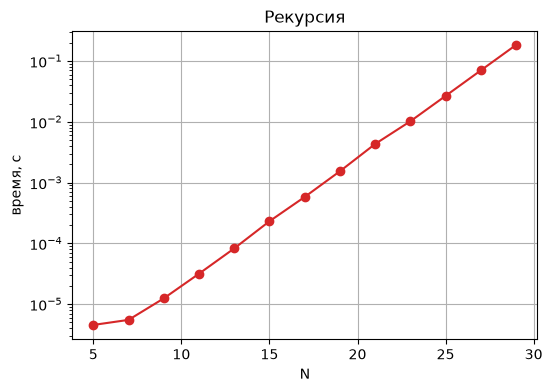

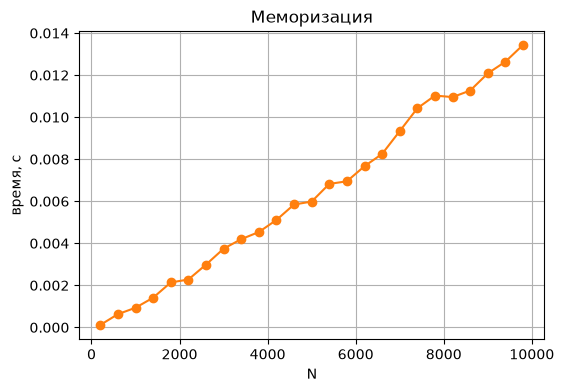

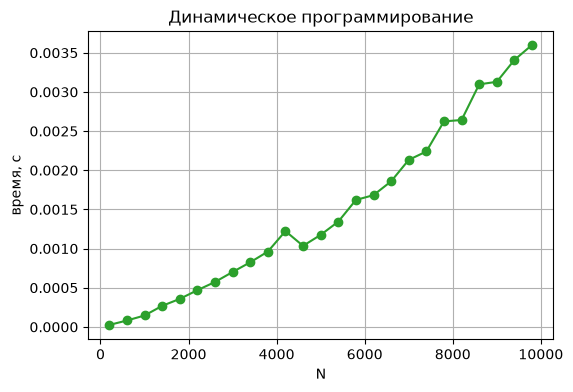

In [6]:
import sys, time
import matplotlib.pyplot as plt
sys.setrecursionlimit(20000)

def fib_rec(n):
    return n if n < 2 else fib_rec(n - 1) + fib_rec(n - 2)

def fib_memo(n, c={}):
    if n < 2:
        return n
    if n in c:
        return c[n]
    c[n] = fib_memo(n - 1, c) + fib_memo(n - 2, c)
    return c[n]

def fib_dp(n):
    a, b = 0, 1
    for _ in range(n):
        a, b = b, a + b
    return a

for n in [10, 20, 30]:
    print(n, fib_rec(n), fib_memo(n), fib_dp(n))

Ns_rec = list(range(5, 31, 2))
t_rec = []
for n in Ns_rec:
    t0 = time.perf_counter()
    fib_rec(n)
    t_rec.append(time.perf_counter() - t0)

plt.figure(figsize=(6, 4))
plt.plot(Ns_rec, t_rec, 'o-', color='tab:red')
plt.yscale('log')
plt.xlabel('N'); plt.ylabel('время, с')
plt.title('Рекурсия')
plt.grid(True); plt.show()

Ns_big = list(range(200, 10001, 400))
t_memo = []
for n in Ns_big:
    t0 = time.perf_counter()
    fib_memo(n, {})
    t_memo.append(time.perf_counter() - t0)

plt.figure(figsize=(6, 4))
plt.plot(Ns_big, t_memo, 'o-', color='tab:orange')
plt.xlabel('N'); plt.ylabel('время, с')
plt.title('Меморизация')
plt.grid(True); plt.show()

t_dp = []
for n in Ns_big:
    t0 = time.perf_counter()
    fib_dp(n)
    t_dp.append(time.perf_counter() - t0)

plt.figure(figsize=(6, 4))
plt.plot(Ns_big, t_dp, 'o-', color='tab:green')
plt.xlabel('N'); plt.ylabel('время, с')
plt.title('Динамическое программирование')
plt.grid(True); plt.show()

### Результат части 2
Все три метода дают одинаковые значения. Рекурсия растёт экспоненциально
по $N$; меморизация и ДП — линейно, причём ДП не тратит память на кеш и
стек вызовов.

In [5]:
p = [72, 120, 144, 84, 66, 108]
a = [12, 24, 36, 30, 27, 42]
B = 60
n = len(p)

def knapsack_dp(p, a, B):
    n = len(p)
    V = [[0] * (B + 1) for _ in range(n + 1)]
    for k in range(1, n + 1):
        for b in range(B + 1):
            V[k][b] = V[k - 1][b]
            if a[k - 1] <= b:
                V[k][b] = max(V[k][b], p[k - 1] + V[k - 1][b - a[k - 1]])
    b, items = B, []
    for k in range(n, 0, -1):
        if V[k][b] != V[k - 1][b]:
            items.append(k)
            b -= a[k - 1]
    return V[n][B], sorted(items)

def knapsack_greedy(p, a, B):
    order = sorted(range(len(p)), key=lambda i: p[i] / a[i], reverse=True)
    w, v, items = 0, 0, []
    for i in order:
        if w + a[i] <= B:
            w += a[i]; v += p[i]; items.append(i + 1)
    return v, sorted(items)

v_dp, items_dp = knapsack_dp(p, a, B)
v_greedy, items_greedy = knapsack_greedy(p, a, B)
print("DP:", v_dp, items_dp)
print("Greedy:", v_greedy, items_greedy)

DP: 264 [2, 3]
Greedy: 192 [1, 2]


### Результат части 3
$V(6,60)=264$ — набор $\{2,3\}$, вес $24+36=60$, вместимость использована
полностью. Жадный алгоритм по $p_k/a_k$ даёт набор $\{1,2\}$, вес $36$,
ценность $192$ — хуже оптимума на $72$: остаток вместимости $24$ не
заполнен, хотя более дешёвые по удельной ценности предметы могли бы его
занять с большей общей выгодой.